# Download Dataset

In [ ]:
!git clone https://github.com/fruits-360/fruits-360-100x100.git

Cloning into 'fruits-360-100x100'...
remote: Enumerating objects: 190158, done.
remote: Counting objects: 100% (13736/13736), done.
remote: Compressing objects: 100% (13709/13709), done.
remote: Total 190158 (delta 43), reused 13719 (delta 27), pack-reused 176422 (from 2)
Receiving objects: 100% (190158/190158), 1.09 GiB | 28.96 MiB/s, done.
Resolving deltas: 100% (467/467), done.
Updating files: 100% (187403/187403), done.


In [ ]:
!git clone https://github.com/fruits-360/fruits-360-original-size.git

Cloning into 'fruits-360-original-size'...
remote: Enumerating objects: 109413, done.
remote: Total 109413 (delta 0), reused 0 (delta 0), pack-reused 109413 (from 1)
Receiving objects: 100% (109413/109413), 3.86 GiB | 34.23 MiB/s, done.
Resolving deltas: 100% (1046/1046), done.
Updating files: 100% (107009/107009), done.


# Define dataset paths

In [ ]:
import os
from pathlib import Path

BASE_DIR = Path("/content/fruits-360-100x100")
TRAIN_DIR = os.path.join(BASE_DIR, "Training")
TEST_DIR = os.path.join(BASE_DIR, "Test")

In [ ]:
print(f"Base Dir: {BASE_DIR}")
print(f"Train Dir: {TRAIN_DIR}")
print(f"Test Dir: {TEST_DIR}")

Base Dir: /content/fruits-360-100x100
Train Dir: /content/fruits-360-100x100/Training
Test Dir: /content/fruits-360-100x100/Test


# About dataset

## Helper function to go through the directory

In [ ]:
import os
def walk_through_dir(dir_path):
  """
  Walks through dir_path returning its contents.
  Args:
    dir_path (str or pathlib.Path): target directory

  Returns:
    A print out of:
      number of subdiretories in dir_path
      number of images (files) in each subdirectory
      name of each subdirectory
  """
  for dirpath, dirnames, filenames in os.walk(dir_path):
    print(f"There are {len(dirnames)} directories and {len(filenames)} images in '{dirpath}'.")

In [ ]:
walk_through_dir(BASE_DIR)

There are 3 directories and 2 images in '/content/fruits-360-100x100'.
There are 265 directories and 0 images in '/content/fruits-360-100x100/Training'.
There are 0 directories and 492 images in '/content/fruits-360-100x100/Training/Apricot 1'.
There are 0 directories and 709 images in '/content/fruits-360-100x100/Training/Cucumber 7'.
There are 0 directories and 900 images in '/content/fruits-360-100x100/Training/Plum 3'.
There are 0 directories and 729 images in '/content/fruits-360-100x100/Training/Mushroom champignon 3'.
There are 0 directories and 469 images in '/content/fruits-360-100x100/Training/Grape 1'.
There are 0 directories and 240 images in '/content/fruits-360-100x100/Training/Eggplant long 1'.
There are 0 directories and 710 images in '/content/fruits-360-100x100/Training/Mushroom champignon 4'.
There are 0 directories and 492 images in '/content/fruits-360-100x100/Training/Apple Braeburn 1'.
There are 0 directories and 450 images in '/content/fruits-360-100x100/Trainin

## Helper funtion to analyse dataset

In [ ]:
import os
from collections import Counter
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


class DatasetAnalyzer:

    def __init__(self, root_dir):
        """Initializes the analyzer by automatically scanning train, test,

        and optional val folders under the root directory.
        """
        self.root_dir = root_dir
        self.splits = ["Training", "Test", "Validation"]

        # Placeholders for data
        self.summary_data = []
        self.class_counts_dict = {
            s: {} for s in self.splits
        }  # {split: {class: count}}
        self.extensions_dict = {
            s: Counter() for s in self.splits
        }  # {split: Counter}

        # DataFrames populated after analysis
        self.df_summary = pd.DataFrame()
        self.df_classes = pd.DataFrame()
        self.df_extensions = pd.DataFrame()

        # Run the internal scanning engine
        self._analyze()

    def get_dataset_size(self):
      """Return the total size of the dataset in MB for a based on the given path of the dataset(root)"""
      total_size = 0
      for dirpath, _, filenames in os.walk(self.root_dir):
          for f in filenames:
              fp = os.path.join(dirpath, f)
              if not os.path.islink(fp):
                  total_size += os.path.getsize(fp)

      # Convert bytes to Megabytes
      size_in_mb = total_size / (1024 * 1024)
      return size_in_mb

    def _analyze(self):
        """Internal method to crawl directories and compile DataFrames."""
        all_detected_classes = set()
        all_detected_extensions = set()

        for split in self.splits:
            split_dir = os.path.join(self.root_dir, split)

            # Skip gracefully if 'val' (or any other split) does not exist
            if not os.path.exists(split_dir):
                continue

            total_files = 0
            total_classes = 0

            for dirpath, dirnames, filenames in os.walk(split_dir):
                # Ensure it's a leaf/class folder (contains files, no subdirectories)
                if len(dirnames) == 0:
                    class_name = os.path.basename(dirpath)
                    file_count = len(filenames)

                    self.class_counts_dict[split][class_name] = file_count
                    all_detected_classes.add(class_name)
                    total_files += file_count
                    total_classes += 1

                    for filename in filenames:
                        ext = os.path.splitext(filename)[1].lower().lstrip(".")
                        if ext:
                            self.extensions_dict[split][ext] += 1
                            all_detected_extensions.add(ext)

            if total_classes > 0 or total_files > 0:
                self.summary_data.append(
                    {
                        "Split": split.capitalize(),
                        "Total Classes": total_classes,
                        "Total Files": total_files,
                    }
                )

        # 1. Build df_summary
        self.df_summary = pd.DataFrame(self.summary_data)

        # 2. Build df_classes
        class_rows = []
        for cls in sorted(all_detected_classes):
            row = {"Class Name": cls}
            total = 0
            for split in self.splits:
                count = self.class_counts_dict[split].get(cls, 0)
                row[f"{split.capitalize()} Count"] = count
                total += count
            row["Total"] = total
            class_rows.append(row)
        self.df_classes = pd.DataFrame(class_rows)

        # 3. Build df_extensions
        ext_rows = []
        for ext in sorted(all_detected_extensions):
            row = {"Extension": ext}
            for split in self.splits:
                row[f"{split.capitalize()} Count"] = self.extensions_dict[
                    split
                ].get(ext, 0)
            ext_rows.append(row)
        self.df_extensions = pd.DataFrame(ext_rows)

    def get_len(self):
        """Returns the total number of files across all detected splits."""
        return self.df_summary["Total Files"].sum()

    def get_extension(self):
        """Returns a DataFrame containing file extension distribution for all splits."""
        # Filter columns to only show active splits that contain data
        active_cols = ["Extension"] + [
            c for c in self.df_extensions.columns if "Count" in c
        ]
        return self.df_extensions[active_cols]

    def get_class(self):
        """Returns a list of unique class names identified in the dataset."""
        return self.df_classes["Class Name"].tolist()

    def get_class_and_count(self):
        """Returns a DataFrame breaking down image counts per class side-by-side

        for all detected splits.
        """
        active_cols = ["Class Name"] + [
            c for c in self.df_classes.columns if "Count" in c or c == "Total"
        ]
        return self.df_classes[active_cols]

    def get_split(self):
        """Returns a summary DataFrame showing class and file metrics per split."""
        return self.df_summary

    def get_missing_classes(self):
        """Returns a DataFrame containing classes that are missing samples in at least one of the active splits.
        """
        count_cols = [c for c in self.df_classes.columns if "Count" in c]
        # Check if any split count is exactly 0
        missing_mask = (self.df_classes[count_cols] == 0).any(axis=1)
        return self.df_classes[missing_mask]

    def plot_dataset_metrics(self):
        """Generates comprehensive layout charts including a focus on missing samples."""
        sns.set_theme(style="whitegrid")

        # Expanded grid (3 rows now) to cleanly include missing samples tracking
        fig = plt.figure(figsize=(16, 18))
        grid = fig.add_gridspec(3, 2, height_ratios=[1, 2, 1.2])

        # Plot A: Overall Dataset Split Balance
        ax0 = fig.add_subplot(grid[0, 0])
        ax0.pie(
            self.df_summary["Total Files"],
            labels=self.df_summary["Split"],
            autopct="%1.1f%%",
            startangle=140,
            colors=sns.color_palette("muted")[: len(self.df_summary)],
        )
        ax0.set_title(
            f"Dataset File Split Ratio\n(Total Files: {self.get_len():,})"
        )

        # Plot B: Global Profile Curve
        ax1 = fig.add_subplot(grid[0, 1])
        df_sorted_total = self.df_classes.sort_values(
            by="Total", ascending=False
        )
        ax1.fill_between(
            range(len(df_sorted_total)),
            df_sorted_total["Total"],
            color="purple",
            alpha=0.4,
        )
        ax1.set_title(
            f"Global Class Size Distribution Profile ({len(self.df_classes)} Classes)"
        )
        ax1.set_xlabel("Sorted Classes (Highest to Lowest)")
        ax1.set_ylabel("Total Samples")

        # Melt logic corrected to handle exact column names cleanly
        count_cols = [c for c in self.df_classes.columns if "Count" in c]
        df_melted = self.df_classes.melt(
            id_vars=["Class Name", "Total"],
            value_vars=count_cols,
            var_name="Split",
            value_name="Count",
        )
        df_melted["Split"] = df_melted["Split"].str.replace(" Count", "")

        # Plot C: Top 20 Largest Classes
        ax2 = fig.add_subplot(grid[1, 0])
        top_20_classes = self.df_classes.nlargest(20, "Total")["Class Name"]
        df_top20 = df_melted[df_melted["Class Name"].isin(top_20_classes)]
        sns.barplot(
            data=df_top20,
            y="Class Name",
            x="Count",
            hue="Split",
            ax=ax2,
            order=top_20_classes,
        )
        ax2.set_title("Top 20 Largest Classes Breakdown")
        ax2.set_xlabel("Number of Images")

        # Plot D: Bottom 20 Smallest Classes
        ax3 = fig.add_subplot(grid[1, 1])
        bottom_20_classes = self.df_classes.nsmallest(20, "Total")["Class Name"]
        df_bottom20 = df_melted[df_melted["Class Name"].isin(bottom_20_classes)]
        sns.barplot(
            data=df_bottom20,
            y="Class Name",
            x="Count",
            hue="Split",
            ax=ax3,
            order=bottom_20_classes,
        )
        ax3.set_title("Bottom 20 Smallest Classes Breakdown")
        ax3.set_xlabel("Number of Images")

        # Plot E: Missing Samples Audit (NEW SECTION)
        ax4 = fig.add_subplot(grid[2, :])  # Span across both columns
        df_missing = self.get_missing_classes()

        if df_missing.empty:
            ax4.text(
                0.5,
                0.5,
                "Perfect Balance: No classes are missing samples in any split!",
                ha="center",
                va="center",
                fontsize=14,
                color="green",
                weight="bold",
            )
            ax4.set_title("Split Integrity & Missing Samples Check")
            ax4.xaxis.grid(False)
            ax4.yaxis.grid(False)
        else:
            # Show up to 15 missing classes to keep chart readable
            df_missing_plot = df_missing.head(15)
            df_missing_melted = df_missing_plot.melt(
                id_vars=["Class Name"],
                value_vars=count_cols,
                var_name="Split",
                value_name="Count",
            )
            df_missing_melted["Split"] = df_missing_melted["Split"].str.replace(
                " Count", ""
            )

            sns.barplot(
                data=df_missing_melted,
                x="Class Name",
                y="Count",
                hue="Split",
                ax=ax4,
            )
            ax4.set_title(
                f"Missing Samples Audit (Showing {len(df_missing_plot)} of {len(df_missing)} incomplete classes)"
            )
            ax4.set_xlabel("Class Name")
            ax4.set_ylabel("File Count")
            plt.setp(ax4.get_xticklabels(), rotation=45, ha="right")

        plt.tight_layout()
        plt.show()

In [ ]:
# Initialize with just your root directory path
analyzer = DatasetAnalyzer(BASE_DIR)

In [ ]:
print(f"Toal size of the dataset: {analyzer.get_dataset_size()}")

Toal size of the dataset: 1944.7133531570435


In [ ]:
# Print Length
print(f"Total Images: {analyzer.get_len()}")

Total Images: 187401


In [ ]:
# Print total class and total file count
print(analyzer.get_split().to_string(index=False))

   Split  Total Classes  Total Files
Training            265       140567
    Test            265        46834


In [ ]:
# Print file extension
print(analyzer.get_extension().to_string(index=False))

Extension  Training Count  Test Count  Validation Count
      jpg          140567       46834                 0


In [ ]:
# Print Class names
print(analyzer.get_class()[:10])

['Almonds 1', 'Apple 10', 'Apple 11', 'Apple 12', 'Apple 13', 'Apple 14', 'Apple 17', 'Apple 18', 'Apple 19', 'Apple 20']


In [ ]:
# Print missing samples
print(analyzer.get_missing_classes())

           Class Name  Training Count  Test Count  Validation Count  Total
0           Almonds 1             232          77                 0    309
1            Apple 10             699         231                 0    930
2            Apple 11             430         142                 0    572
3            Apple 12             466         154                 0    620
4            Apple 13             699         235                 0    934
..                ...             ...         ...               ...    ...
261      Watermelon 1             475         157                 0    632
262        Zucchini 1             240          80                 0    320
263  Zucchini Green 1             144          47                 0    191
264   Zucchini dark 1             383         127                 0    510
265          orange 4             948         316                 0   1264

[266 rows x 5 columns]


In [ ]:
# Print classe names, their count in all the splits
print(analyzer.get_class_and_count().head(10))

  Class Name  Training Count  Test Count  Validation Count  Total
0  Almonds 1             232          77                 0    309
1   Apple 10             699         231                 0    930
2   Apple 11             430         142                 0    572
3   Apple 12             466         154                 0    620
4   Apple 13             699         235                 0    934
5   Apple 14             466         154                 0    620
6   Apple 17             610         201                 0    811
7   Apple 18             724         240                 0    964
8   Apple 19             729         241                 0    970
9   Apple 20             702         234                 0    936


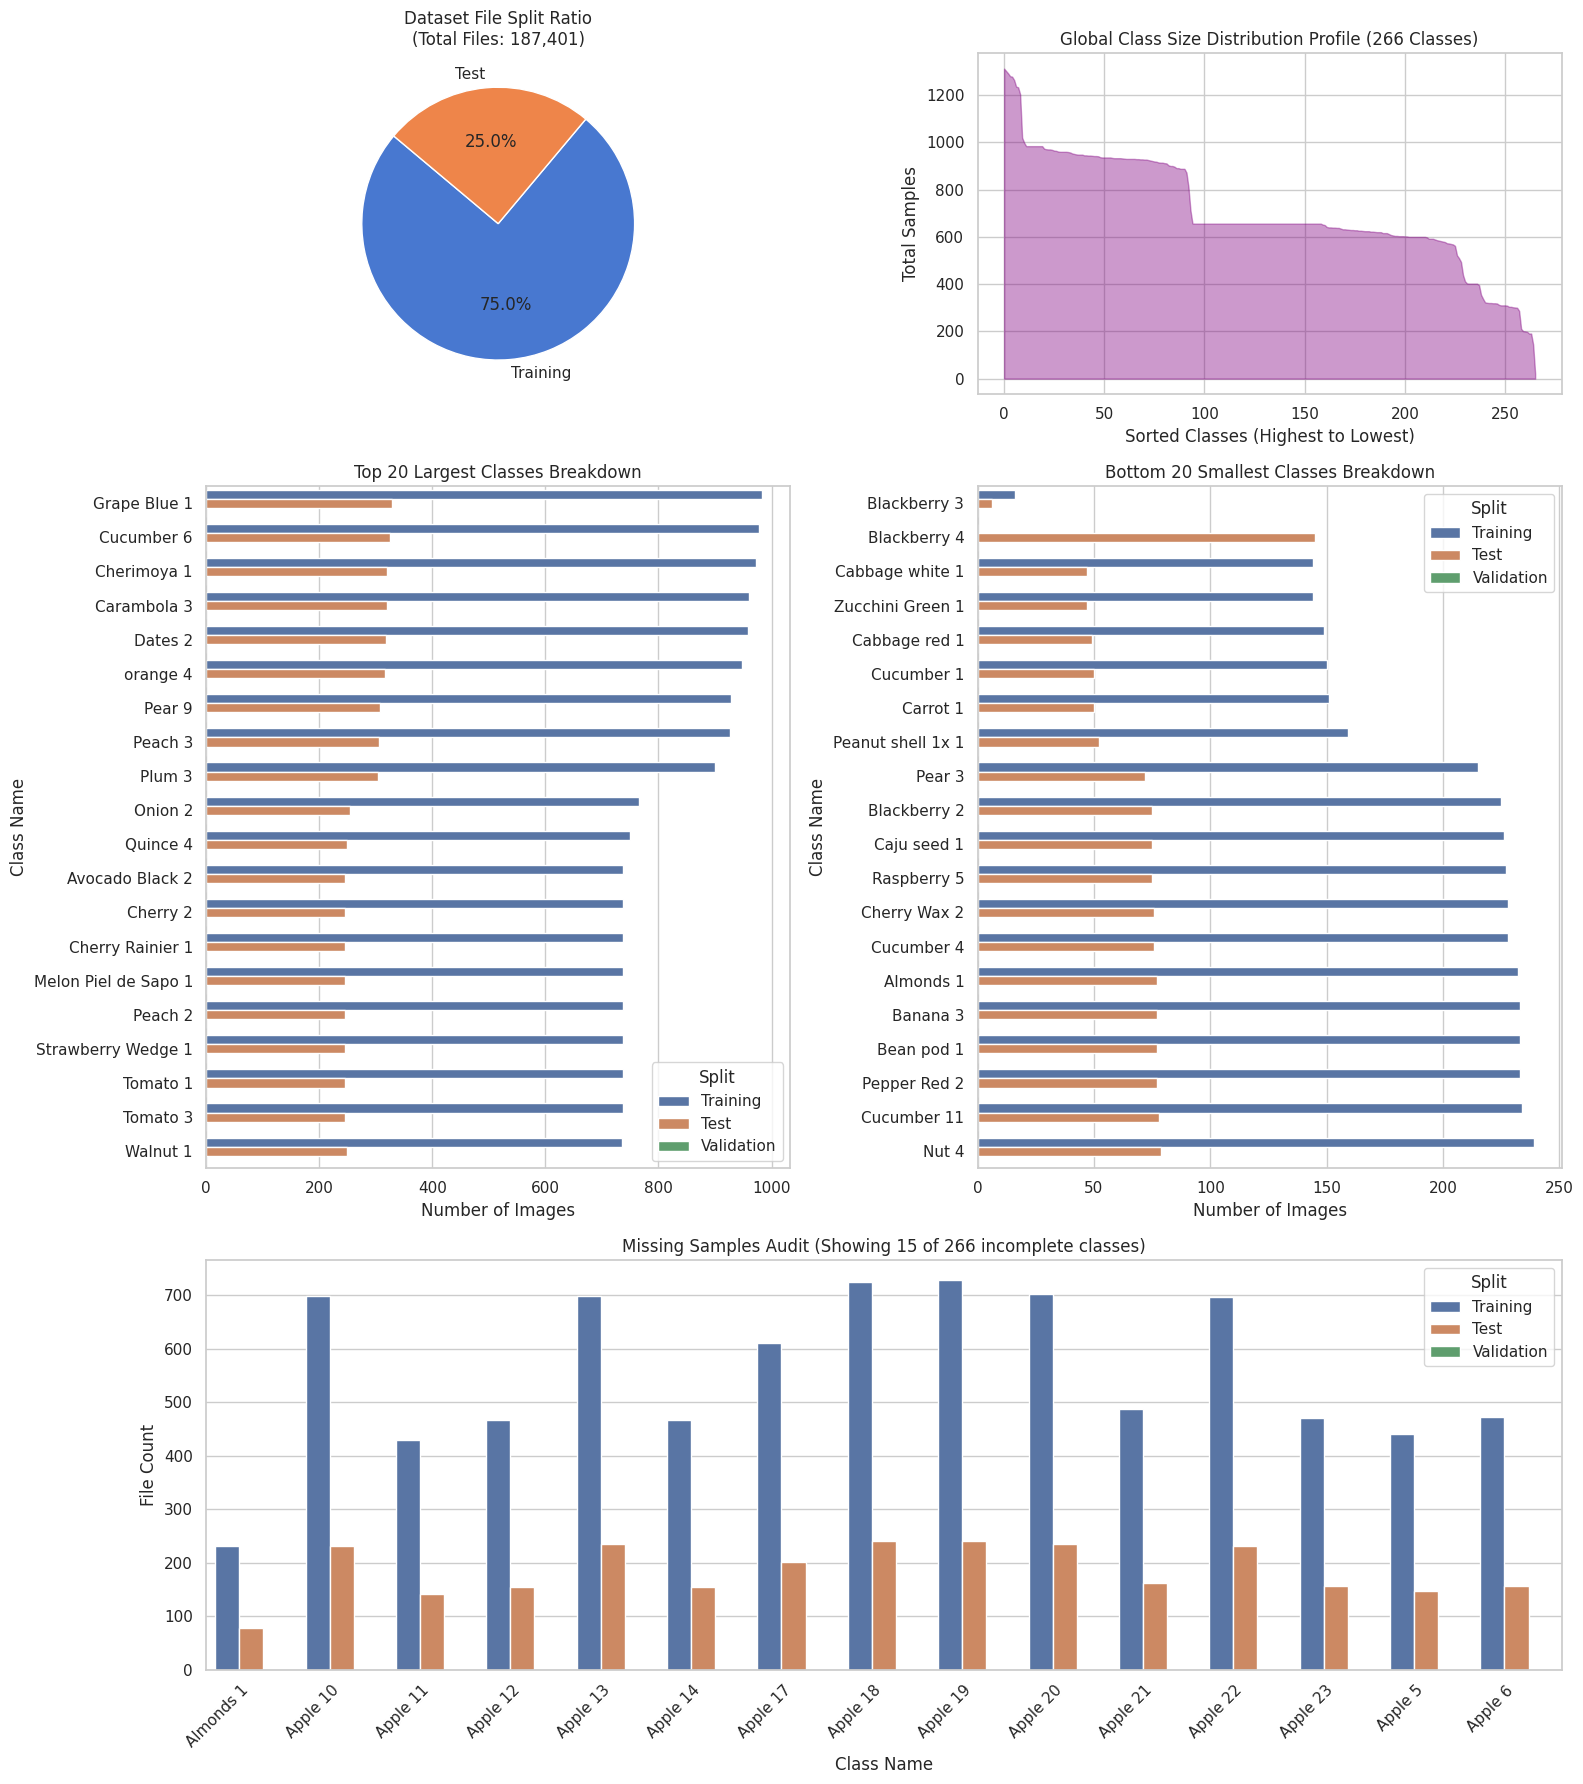

In [ ]:
# Plot metrics
analyzer.plot_dataset_metrics()

## Helper function to view samples

In [ ]:
import os
import random
from PIL import Image
import matplotlib.pyplot as plt

class AnalyzeImage:
    def __init__(self, root_dir):
        """
        Initializes the analyzer by scanning for image paths inside the root directory.
        """
        self.root_dir = root_dir
        self.img_paths = self._get_image_paths()

    def _get_image_paths(self):
        """
        Internal helper to recursively scan the root directory and find all files.
        """
        img_paths = []
        for dirpath, dirnames, filenames in os.walk(self.root_dir):
            # Skip the root directory itself
            if dirpath == self.root_dir:
                continue
            # Check if this folder contains ONLY files (leaf directories)
            if len(dirnames) == 0:
                img_paths.extend(os.path.join(dirpath, filename) for filename in filenames)
        return img_paths

    def get_len(self):
        """
        Returns the total number of discovered images.
        """
        return len(self.img_paths)

    def get_properties(self, sample_index=0):
        """
        Returns structural details of an image at a specific index.
        """
        if not self.img_paths:
            return "No images found in the specified directory."

        try:
            path = self.img_paths[sample_index]
            with Image.open(path) as img:
                width, height = img.size
                channels = img.getbands()

                # Derive split from path structure (assuming standard datasets)
                split_name = "Unknown"
                for split in ["train", "test", "val", "validation"]:
                    if split in path.lower():
                        split_name = split.capitalize()
                        break

                return {
                    "Split": split_name,
                    "Class": os.path.basename(os.path.dirname(path)),
                    "Width": f"{width}px",
                    "Height": f"{height}px",
                    "Channels": f"{len(channels)} ({channels})",
                    "Format Mode": img.mode
                }
        except Exception as e:
            return f"Error reading image properties: {str(e)}"

    def plot_sample(self, train=True, test=False, val=False, no_of_sample_to_plot=3, class_to_plot=None):
        """
        Dynamically filters and randomly plots samples based on active splits, counts, and class constraints.
        """
        # 1. Validation guards
        if not (train or test or val):
            raise ValueError("At least one split (train, test, or val) must be set to True.")
        if no_of_sample_to_plot < 1:
            raise ValueError("no_of_sample_to_plot must be at least 1.")

        # 2. Filter images dynamically based on criteria
        filtered_paths = []
        for path in self.img_paths:
            path_lower = path.lower()
            class_name = os.path.basename(os.path.dirname(path))

            # Class filter
            if class_to_plot != None and class_name.lower() != class_to_plot.lower():
                continue

            # Split filter
            if train and ("train" in path_lower or "training" in path_lower):
                filtered_paths.append((path, "Train"))
            elif test and ("test" in path_lower or "testing" in path_lower):
                filtered_paths.append((path, "Test"))
            elif val and ("val" in path_lower or "validation" in path_lower):
                filtered_paths.append((path, "Validation"))

        if not filtered_paths:
            print("No images matched the given filter criteria.")
            return

        # 3. Handle sampling boundaries gracefully
        samples_to_take = min(no_of_sample_to_plot, len(filtered_paths))
        sampled_items = random.sample(filtered_paths, samples_to_take)

        # 4. Dynamic Grid Plot Setup
        cols = 5 if samples_to_take >= 5 else samples_to_take
        rows = (samples_to_take + cols - 1) // cols  # Ceiling division

        fig, axs = plt.subplots(rows, cols, figsize=(cols * 3, rows * 3))

        # Standardise axs array for consistent looping
        if samples_to_take == 1:
            axs = [axs]
        else:
            axs = axs.flatten()

        # 5. Populate and render the plots
        for i, (path, split_lbl) in enumerate(sampled_items):
            try:
                img = Image.open(path)
                class_lbl = os.path.basename(os.path.dirname(path))

                axs[i].imshow(img)
                axs[i].set_title(f"Split: {split_lbl}\nClass: {class_lbl}", fontsize=9)
                axs[i].axis('off')
            except Exception as e:
                axs[i].text(0.5, 0.5, f"Error\n{str(e)}", ha='center', va='center')
                axs[i].axis('off')

        # Clear out any leftover empty subplots in the grid layout
        for j in range(i + 1, len(axs)):
            fig.delaxes(axs[j])

        plt.tight_layout()
        plt.show()

In [ ]:
# Initialize the analyzer
analyzer = AnalyzeImage(BASE_DIR)

In [ ]:
# Get total length
print("Total images:", analyzer.get_len())

Total images: 187423


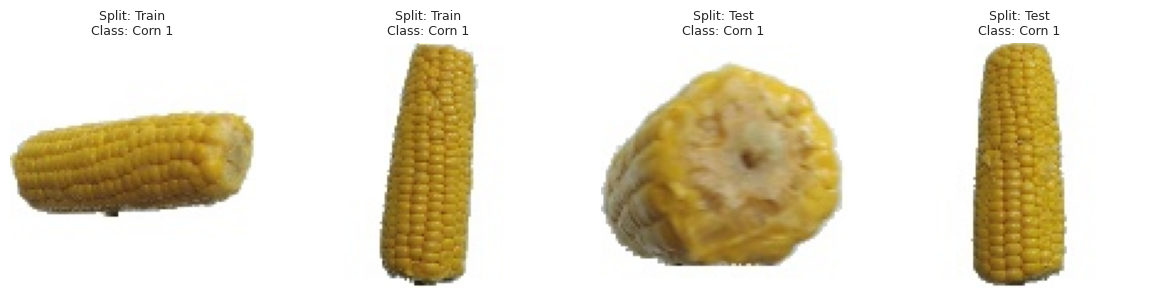

In [ ]:
# Plot samples from train and test splits
analyzer.plot_sample(train=True, test=True, val=True, no_of_sample_to_plot=4, class_to_plot = "Corn 1")

In [ ]:
# Get properties of the first image
print(analyzer.get_properties(0))

{'Split': 'Train', 'Class': 'Apricot 1', 'Width': '100px', 'Height': '100px', 'Channels': "3 (('R', 'G', 'B'))", 'Format Mode': 'RGB'}


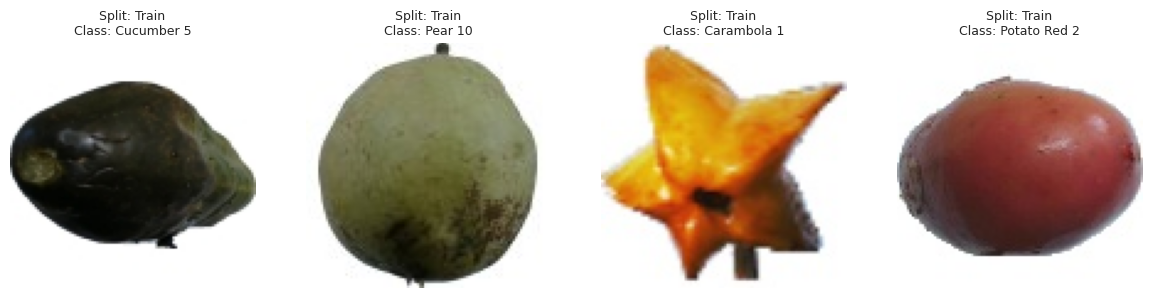

In [ ]:
# Plot samples from train and test splits
analyzer.plot_sample(train=True, test=False, val=False, no_of_sample_to_plot=4, class_to_plot = None)

# Clean Dataset

Yet to implement not all dataset are having missing samples. The only dataset that have missing  samples is `fruits-360-original-size`

# Create Image Folder

## Setup train and test paths

In [ ]:
train_dir = BASE_DIR / "Training"
test_dir = BASE_DIR / "Test"

train_dir, test_dir

(PosixPath('/content/fruits-360-100x100/Training'),
 PosixPath('/content/fruits-360-100x100/Test'))

## Create transforms

In [ ]:
import torch
from torchvision import datasets
from torchvision.transforms import v2
from torch.utils.data import DataLoader

**Note:** Since our dataset is already rotated and resized to 100x100 we did not use `transforms.Resize(100, 100)` and `transforms.RandomhorizontalFlip(p=0.3)`

> r?_image_index.jpg (e.g. r2_31.jpg).
    
where "r" stands for rotated fruit. "r2" means that the fruit was rotated around the 3rd axis.

In [ ]:
# Write transform for image
data_transform = v2.Compose([

    # Converts PIL to Tensor image (C, H, W)
    v2.ToImage(),

    # Turn the image into a torch.Tensor and brings values to 0.0 - 1.0
    v2.ToDtype(dtype=torch.float32, scale=True)
])

In [ ]:
data_tranform_normalized = v2.Compose([

    # Converts PIL to Tensor image (C, H, W)
    v2.ToImage(),

    # Turn the image into a torch.Tensor and brings values to 0.0 - 1.0
    v2.ToDtype(dtype=torch.float32, scale=True),

    # Normalize the image to improve the training speed
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [ ]:
train_transform_100_x_100 = v2.Compose([

    # Need to Resize if working on fruits-360-original-size
    v2.Resize((100, 100)),

    # Converts PIL to Tensor image (C, H, W)
    v2.ToImage(),

    # Turn the image into a torch.Tensor and brings values to 0.0 - 1.0
    v2.ToDtype(dtype=torch.float32, scale=True)
])

In [ ]:
train_transforms_augment_100_x_100 = v2.Compose([

    # Need to Resize if working on fruits-360-original-size
    v2.Resize((100, 100)),

    # State-of-the art augmentation technique. randomly chooses exactly one
    # augmentation operation from a predefined list (e.g., Rotate, Shear, Contrast, Brightness)
    # and randomly picks a magnitude for that operation uniformly from a given range.
    v2.TrivialAugmentWide(
        num_magnitude_bins=31,
        interpolation=v2.InterpolationMode.BILINEAR,
        fill=0
    ),

    # Converts PIL to Tensor image (C, H, W)
    v2.ToImage(),

    # Turn the image into a torch.Tensor and brings values to 0.0 - 1.0
    v2.ToDtype(dtype=torch.float32, scale=True)
])

## Plot transformed samples

In [ ]:
def plot_transformed_images(image_paths, transform, n=3, seed=42):
    """Plots a series of random images from image_paths.

    Will open n image paths from image_paths, transform them
    with transform and plot them side by side.

    Args:
        image_paths (list): List of target image paths.
        transform (PyTorch Transforms): Transforms to apply to images.
        n (int, optional): Number of images to plot. Defaults to 3.
        seed (int, optional): Random seed for the random generator. Defaults to 42.
    """
    random.seed(seed)
    random_image_paths = random.sample(image_paths, k=n)
    for image_path in random_image_paths:
        with Image.open(image_path) as f:
            fig, ax = plt.subplots(1, 2)
            ax[0].imshow(f)
            ax[0].set_title(f"Original \nSize: {f.size}")
            ax[0].axis("off")

            # Transform and plot image
            # Note: permute() will change shape of image to suit matplotlib
            # (PyTorch default is [C, H, W] but Matplotlib is [H, W, C])
            transformed_image = transform(f).permute(1, 2, 0)
            ax[1].imshow(transformed_image)
            ax[1].set_title(f"Transformed \nSize: {transformed_image.shape}")
            ax[1].axis("off")

            fig.suptitle(f"Class: {os.path.basename(os.path.dirname(image_path))}", fontsize=16)

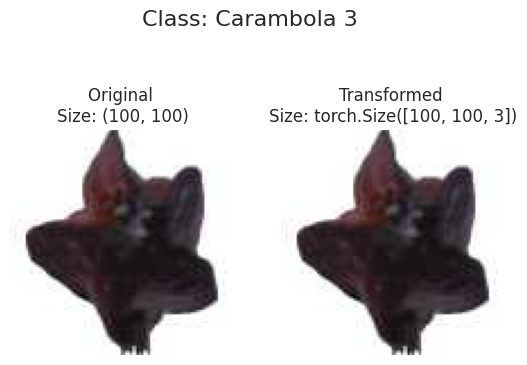

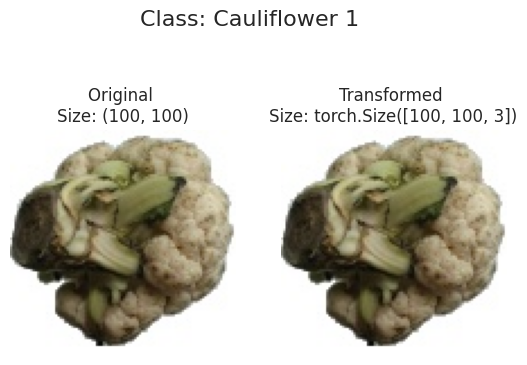

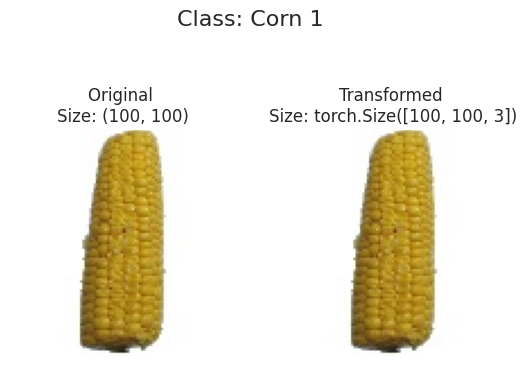

In [ ]:
img_paths = analyzer._get_image_paths()
plot_transformed_images(img_paths,
                        transform=data_transform,
                        n=3)

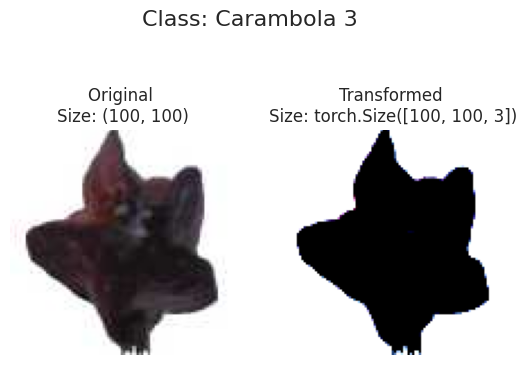

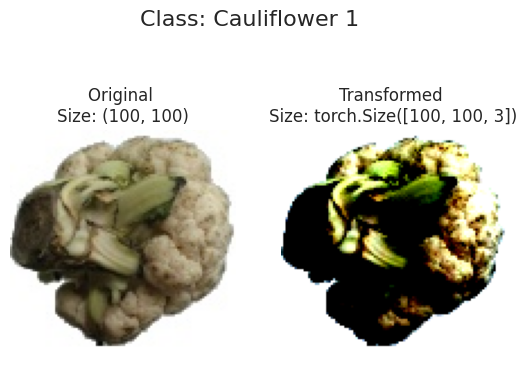

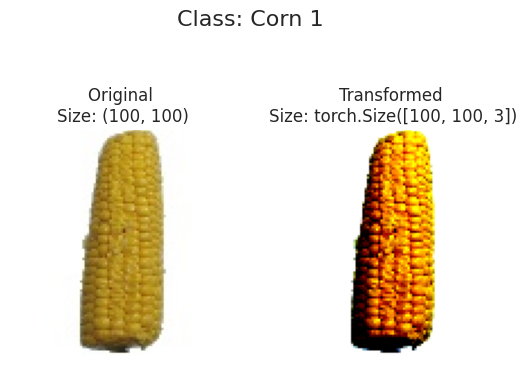

In [ ]:
img_paths = analyzer._get_image_paths()
plot_transformed_images(img_paths,
                        transform=data_tranform_normalized,
                        n=3)

## Loading Image Data Using [ImageFolder](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.ImageFolder.html#torchvision.datasets.ImageFolder)

we can use the class [torchvision.datasets.ImageFolder](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.ImageFolder.html#torchvision.datasets.ImageFolder)

In [ ]:
# Use ImageFolder to create dataset(s)
from torchvision import datasets
train_data = datasets.ImageFolder(root=train_dir, # target folder of images
                                  transform=data_transform, # transforms to perform on data (images)
                                  target_transform=None) # transforms to perform on labels (if necessary)

test_data = datasets.ImageFolder(root=test_dir,
                                 transform=data_transform)

print(f"Train data:\n{train_data}\nTest data:\n{test_data}")

Train data:
Dataset ImageFolder
    Number of datapoints: 140567
    Root location: /content/fruits-360-100x100/Training
    StandardTransform
Transform: Compose(
                 ToImage()
                 ToDtype(scale=True)
           )
Test data:
Dataset ImageFolder
    Number of datapoints: 46834
    Root location: /content/fruits-360-100x100/Test
    StandardTransform
Transform: Compose(
                 ToImage()
                 ToDtype(scale=True)
           )


In [ ]:
# Get class names as a list
class_names = train_data.classes
print(f"Class names: {class_names}")
print(f"Class names count: {len(class_names)}")

# # Can also get class names as a dict
# class_dict = train_data.class_to_idx
# class_dict

Class names: ['Almonds 1', 'Apple 10', 'Apple 11', 'Apple 12', 'Apple 13', 'Apple 14', 'Apple 17', 'Apple 18', 'Apple 19', 'Apple 20', 'Apple 21', 'Apple 22', 'Apple 23', 'Apple 5', 'Apple 6', 'Apple 7', 'Apple 8', 'Apple 9', 'Apple Braeburn 1', 'Apple Crimson Snow 1', 'Apple Golden 1', 'Apple Golden 2', 'Apple Golden 3', 'Apple Granny Smith 1', 'Apple Pink Lady 1', 'Apple Red 1', 'Apple Red 2', 'Apple Red 3', 'Apple Red Delicious 1', 'Apple Red Yellow 1', 'Apple Red Yellow 2', 'Apricot 1', 'Avocado 1', 'Avocado 2', 'Avocado Black 1', 'Avocado Black 2', 'Avocado Green 1', 'Banana 1', 'Banana 3', 'Banana 4', 'Banana Lady Finger 1', 'Banana Red 1', 'Bean pod 1', 'Beetroot 1', 'BlackBerry 3', 'BlackBerry 4', 'Blackberry 1', 'Blackberry 2', 'Blackberry 3', 'Blackberry 5', 'Blueberry 1', 'Cabbage red 1', 'Cabbage white 1', 'Cactus fruit 1', 'Cactus fruit green 1', 'Cactus fruit red 1', 'Caju seed 1', 'Cantaloupe 1', 'Cantaloupe 2', 'Cantaloupe 3', 'Carambola 1', 'Carambola 2', 'Carambola 3'

In [ ]:
# Check the lengths
len(train_data), len(test_data)

(140567, 46834)

In [ ]:
img, label = train_data[0][0], train_data[0][1]
print(f"Image tensor:\n{img}")
print(f"Image shape: {img.shape}")
print(f"Image datatype: {img.dtype}")
print(f"Image label: {label}")
print(f"Label datatype: {type(label)}")

Image tensor:
Image([[[1., 1., 1.,  ..., 1., 1., 1.],
        [1., 1., 1.,  ..., 1., 1., 1.],
        [1., 1., 1.,  ..., 1., 1., 1.],
        ...,
        [1., 1., 1.,  ..., 1., 1., 1.],
        [1., 1., 1.,  ..., 1., 1., 1.],
        [1., 1., 1.,  ..., 1., 1., 1.]],

       [[1., 1., 1.,  ..., 1., 1., 1.],
        [1., 1., 1.,  ..., 1., 1., 1.],
        [1., 1., 1.,  ..., 1., 1., 1.],
        ...,
        [1., 1., 1.,  ..., 1., 1., 1.],
        [1., 1., 1.,  ..., 1., 1., 1.],
        [1., 1., 1.,  ..., 1., 1., 1.]],

       [[1., 1., 1.,  ..., 1., 1., 1.],
        [1., 1., 1.,  ..., 1., 1., 1.],
        [1., 1., 1.,  ..., 1., 1., 1.],
        ...,
        [1., 1., 1.,  ..., 1., 1., 1.],
        [1., 1., 1.,  ..., 1., 1., 1.],
        [1., 1., 1.,  ..., 1., 1., 1.]]], )
Image shape: torch.Size([3, 100, 100])
Image datatype: torch.float32
Image label: 0
Label datatype: <class 'int'>


Original shape: torch.Size([3, 100, 100]) -> [color_channels, height, width]
Image permute shape: torch.Size([100, 100, 3]) -> [height, width, color_channels]


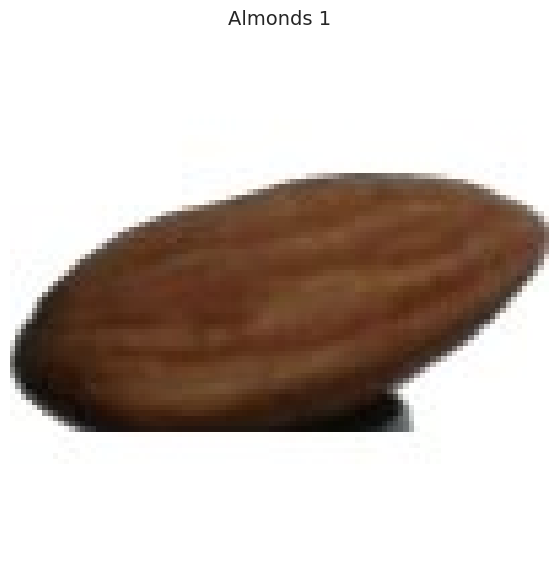

In [ ]:
# Rearrange the order of dimensions
img_permute = img.permute(1, 2, 0)

# Print out different shapes (before and after permute)
print(f"Original shape: {img.shape} -> [color_channels, height, width]")
print(f"Image permute shape: {img_permute.shape} -> [height, width, color_channels]")

# Plot the image
plt.figure(figsize=(10, 7))
plt.imshow(img.permute(1, 2, 0))
plt.axis("off")
plt.title(class_names[label], fontsize=14);

# Turn image folder into DataLoader's

We'll do so using [torch.utils.data.DataLoader](https://docs.pytorch.org/docs/2.14/data.html#torch.utils.data.DataLoader)

In [ ]:
# Setup batch size and number of workers
BATCH_SIZE = 32
NUM_WORKERS = os.cpu_count()

In [ ]:
# Turn train and test Datasets into DataLoaders
from torch.utils.data import DataLoader
train_dataloader = DataLoader(dataset=train_data,
                              batch_size=BATCH_SIZE, # how many samples per batch?
                              num_workers=NUM_WORKERS, # how many subprocesses to use for data loading? (higher = more)
                              shuffle=True) # shuffle the data?

test_dataloader = DataLoader(dataset=test_data,
                             batch_size=BATCH_SIZE,
                             num_workers=NUM_WORKERS,
                             shuffle=False) # don't usually need to shuffle testing data

train_dataloader, test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x7bfdb8886510>,
 <torch.utils.data.dataloader.DataLoader at 0x7bfdb728cb90>)

In [ ]:
img, label = next(iter(train_dataloader))

# Batch size will now be 1, try changing the batch_size parameter above and see what happens
print(f"Image shape: {img.shape} -> [batch_size, color_channels, height, width]")
print(f"Label shape: {label.shape}")

Image shape: torch.Size([32, 3, 100, 100]) -> [batch_size, color_channels, height, width]
Label shape: torch.Size([32])


# Create train & test loop functions

## Train Step

In [ ]:
def train_step(model: torch.nn.Module,
               dataloader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer):
    # Put model in train mode
    model.train()

    # Setup train loss and train accuracy values
    train_loss, train_acc = 0, 0

    # Loop through data loader data batches
    for batch, (X, y) in enumerate(dataloader):
        # Send data to target device
        X, y = X.to(device), y.to(device)

        # 1. Forward pass
        y_pred = model(X)

        # 2. Calculate  and accumulate loss
        loss = loss_fn(y_pred, y)
        train_loss += loss.item()

        # 3. Optimizer zero grad
        optimizer.zero_grad()

        # 4. Loss backward
        loss.backward()

        # 5. Optimizer step
        optimizer.step()

        # Calculate and accumulate accuracy metrics across all batches
        y_pred_class = torch.argmax(torch.softmax(y_pred, dim=1), dim=1)
        train_acc += (y_pred_class == y).sum().item()/len(y_pred)

    # Adjust metrics to get average loss and accuracy per batch
    train_loss = train_loss / len(dataloader)
    train_acc = train_acc / len(dataloader)
    return train_loss, train_acc

## Test Step

In [ ]:
def test_step(model: torch.nn.Module,
              dataloader: torch.utils.data.DataLoader,
              loss_fn: torch.nn.Module):
    # Put model in eval mode
    model.eval()

    # Setup test loss and test accuracy values
    test_loss, test_acc = 0, 0

    # Turn on inference context manager
    with torch.inference_mode():
        # Loop through DataLoader batches
        for batch, (X, y) in enumerate(dataloader):
            # Send data to target device
            X, y = X.to(device), y.to(device)

            # 1. Forward pass
            test_pred_logits = model(X)

            # 2. Calculate and accumulate loss
            loss = loss_fn(test_pred_logits, y)
            test_loss += loss.item()

            # Calculate and accumulate accuracy
            test_pred_labels = test_pred_logits.argmax(dim=1)
            test_acc += ((test_pred_labels == y).sum().item()/len(test_pred_labels))

    # Adjust metrics to get average loss and accuracy per batch
    test_loss = test_loss / len(dataloader)
    test_acc = test_acc / len(dataloader)
    return test_loss, test_acc

## Creating a train() function to combine train_step() and test_step()

In [ ]:
import torch.nn as nn
from tqdm.auto import tqdm

# 1. Take in various parameters required for training and test steps
def train(model: torch.nn.Module,
          train_dataloader: torch.utils.data.DataLoader,
          test_dataloader: torch.utils.data.DataLoader,
          optimizer: torch.optim.Optimizer,
          loss_fn: torch.nn.Module = nn.CrossEntropyLoss(),
          epochs: int = 5):

    # 2. Create empty results dictionary
    results = {"train_loss": [],
        "train_acc": [],
        "test_loss": [],
        "test_acc": []
    }

    # 3. Loop through training and testing steps for a number of epochs
    for epoch in tqdm(range(epochs)):
        train_loss, train_acc = train_step(model=model,
                                           dataloader=train_dataloader,
                                           loss_fn=loss_fn,
                                           optimizer=optimizer)
        test_loss, test_acc = test_step(model=model,
            dataloader=test_dataloader,
            loss_fn=loss_fn)

        # 4. Print out what's happening
        print(
            f"Epoch: {epoch+1} | "
            f"train_loss: {train_loss:.4f} | "
            f"train_acc: {train_acc:.4f} | "
            f"test_loss: {test_loss:.4f} | "
            f"test_acc: {test_acc:.4f}"
        )

        # 5. Update results dictionary
        # Ensure all data is moved to CPU and converted to float for storage
        results["train_loss"].append(train_loss.item() if isinstance(train_loss, torch.Tensor) else train_loss)
        results["train_acc"].append(train_acc.item() if isinstance(train_acc, torch.Tensor) else train_acc)
        results["test_loss"].append(test_loss.item() if isinstance(test_loss, torch.Tensor) else test_loss)
        results["test_acc"].append(test_acc.item() if isinstance(test_acc, torch.Tensor) else test_acc)

    # 6. Return the filled results at the end of the epochs
    return results

# Train and Test TinyVGG Model

## Create TinyVGG Model

In [ ]:
from torch import nn
device = "cuda" if torch.cuda.is_available() else "cpu"

class TinyVGG(nn.Module):
    """
    Model architecture copying TinyVGG from:
    https://poloclub.github.io/cnn-explainer/
    """
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int) -> None:
        super().__init__()
        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(in_channels=input_shape,
                      out_channels=hidden_units,
                      kernel_size=3, # how big is the square that's going over the image?
                      stride=1, # default
                      padding=1), # options = "valid" (no padding) or "same" (output has same shape as input) or int for specific number
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                         stride=2) # default stride value is same as kernel_size
        )
        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(hidden_units, hidden_units, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden_units, hidden_units, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            # Where did this in_features shape come from?
            # It's because each layer of our network compresses and changes the shape of our input data.
            nn.Linear(in_features=hidden_units*25*25,
                      out_features=output_shape)
        )

    def forward(self, x: torch.Tensor):
        x = self.conv_block_1(x)
        # print(x.shape)
        x = self.conv_block_2(x)
        # print(x.shape)
        x = self.classifier(x)
        # print(x.shape)
        return x
        # return self.classifier(self.conv_block_2(self.conv_block_1(x))) # <- leverage the benefits of operator fusion

In [ ]:
torch.manual_seed(42)
model_0 = TinyVGG(input_shape=3, # number of color channels (3 for RGB)
                  hidden_units=10,
                  output_shape=len(train_data.classes)).to(device)
model_0

TinyVGG(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=6250, out_features=263, bias=True)
  )
)

## Try a forward pass on a single image

In [ ]:
# 1. Get a batch of images and labels from the DataLoader
img_batch, label_batch = next(iter(train_dataloader))

# 2. Get a single image from the batch and unsqueeze the image so its shape fits the model
img_single, label_single = img_batch[0].unsqueeze(dim=0), label_batch[0]
print(f"Single image shape: {img_single.shape}\n")

# 3. Perform a forward pass on a single image
model_0.eval()
with torch.inference_mode():
    pred = model_0(img_single.to(device))

# 4. Print out what's happening and convert model logits -> pred probs -> pred label
print(f"Output logits:\n{pred}\n")
print(f"Output prediction probabilities:\n{torch.softmax(pred, dim=1)}\n")
print(f"Output prediction label:\n{torch.argmax(torch.softmax(pred, dim=1), dim=1)}\n")
print(f"Actual label:\n{label_single}")

Single image shape: torch.Size([1, 3, 100, 100])

Output logits:
tensor([[-0.0447,  0.0340, -0.0074,  0.0919, -0.0934,  0.0172,  0.0734,  0.0032,
         -0.0103,  0.0635,  0.0113, -0.0092,  0.0994, -0.0243, -0.0160,  0.0094,
         -0.0532, -0.0435,  0.0302,  0.0486, -0.0204,  0.0108,  0.0614,  0.0193,
         -0.0161,  0.0291,  0.0128,  0.0103, -0.0097, -0.0884,  0.0025, -0.0255,
         -0.0352,  0.0014,  0.0262, -0.0211, -0.0044, -0.0505, -0.0299, -0.0591,
         -0.1083, -0.0208,  0.0110, -0.0036, -0.0073,  0.0227,  0.0392,  0.0123,
         -0.0234,  0.0121, -0.0044, -0.0131,  0.0126, -0.0095, -0.0367, -0.0462,
         -0.0620, -0.0535, -0.0100,  0.0275, -0.0297, -0.0103,  0.0349,  0.0090,
          0.0089,  0.0005, -0.0742, -0.0083, -0.0002, -0.0675, -0.0408,  0.0165,
         -0.0868, -0.0705,  0.0120,  0.0645,  0.0286,  0.0715,  0.0325, -0.0151,
          0.0072,  0.0034,  0.0583,  0.0876,  0.0274, -0.0015, -0.0379, -0.0137,
          0.0122, -0.0481, -0.0137, -0.0667,

## Train Model

In [ ]:
# Set random seeds
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# Set number of epochs
NUM_EPOCHS = 5

# Recreate an instance of TinyVGG
model_0 = TinyVGG(input_shape=3, # number of color channels (3 for RGB)
                  hidden_units=10,
                  output_shape=len(train_data.classes)).to(device)

# Setup loss function and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_0.parameters(), lr=0.001)

# Start the timer
from timeit import default_timer as timer
start_time = timer()

# Train model_0
model_0_results = train(model=model_0,
                        train_dataloader=train_dataloader,
                        test_dataloader=test_dataloader,
                        optimizer=optimizer,
                        loss_fn=loss_fn,
                        epochs=NUM_EPOCHS)

# End the timer and print out how long it took
end_time = timer()
print(f"Total training time: {end_time-start_time:.3f} seconds")

  0%|          | 0/5 [00:00<?, ?it/s]

KeyboardInterrupt: 

## View saved results

In [ ]:
# Check the model_0_results keys
model_0_results.keys()

dict_keys(['train_loss', 'train_acc', 'test_loss', 'test_acc'])

## Plot curves

In [ ]:
from typing import Dict, List

def plot_loss_curves(results: Dict[str, List[float]]):
    """Plots training curves of a results dictionary.

    Args:
        results (dict): dictionary containing list of values, e.g.
            {"train_loss": [...],
             "train_acc": [...],
             "test_loss": [...],
             "test_acc": [...]}
    """

    # Get the loss values of the results dictionary (training and test)
    loss = results['train_loss']
    test_loss = results['test_loss']

    # Get the accuracy values of the results dictionary (training and test)
    accuracy = results['train_acc']
    test_accuracy = results['test_acc']

    # Figure out how many epochs there were
    epochs = range(len(results['train_loss']))

    # Setup a plot
    plt.figure(figsize=(15, 7))

    # Plot loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, loss, label='train_loss')
    plt.plot(epochs, test_loss, label='test_loss')
    plt.title('Loss')
    plt.xlabel('Epochs')
    plt.legend()

    # Plot accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, accuracy, label='train_accuracy')
    plt.plot(epochs, test_accuracy, label='test_accuracy')
    plt.title('Accuracy')
    plt.xlabel('Epochs')
    plt.legend();

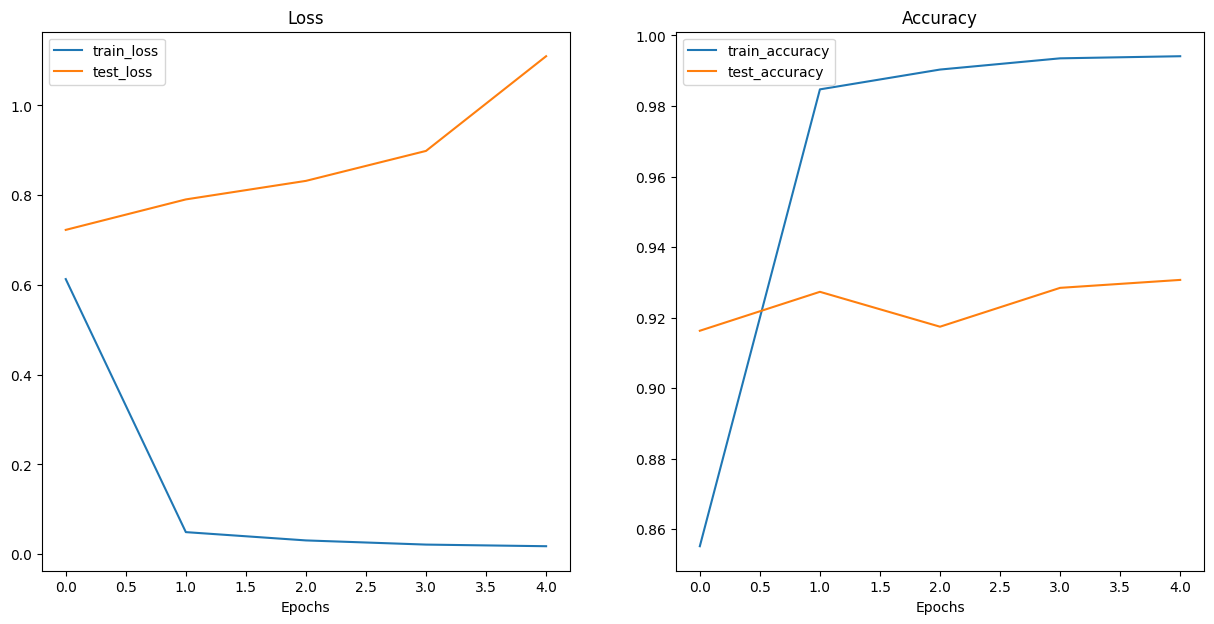

In [ ]:
plot_loss_curves(model_0_results)

## Use torchinfo to get an idea of the shapes going through our model

In [ ]:
# Install torchinfo if it's not available, import it if it is
try:
    import torchinfo
except:
    !pip install torchinfo
    import torchinfo

from torchinfo import summary
summary(model_0, input_size=[1, 3, 64, 64]) # do a test pass through of an example input size

Layer (type:depth-idx)                   Output Shape              Param #
TinyVGG                                  [1, 263]                  --
├─Sequential: 1-1                        [1, 10, 32, 32]           --
│    └─Conv2d: 2-1                       [1, 10, 64, 64]           280
│    └─ReLU: 2-2                         [1, 10, 64, 64]           --
│    └─Conv2d: 2-3                       [1, 10, 64, 64]           910
│    └─ReLU: 2-4                         [1, 10, 64, 64]           --
│    └─MaxPool2d: 2-5                    [1, 10, 32, 32]           --
├─Sequential: 1-2                        [1, 10, 16, 16]           --
│    └─Conv2d: 2-6                       [1, 10, 32, 32]           910
│    └─ReLU: 2-7                         [1, 10, 32, 32]           --
│    └─Conv2d: 2-8                       [1, 10, 32, 32]           910
│    └─ReLU: 2-9                         [1, 10, 32, 32]           --
│    └─MaxPool2d: 2-10                   [1, 10, 16, 16]           --
├─Sequentia

# Train and Test Customize TinyVGG Model

In [ ]:
from torch import nn
device = "cuda" if torch.cuda.is_available() else "cpu"

class DropoutTinyVGG(nn.Module):
    """
    Model architecture copying TinyVGG from:
    https://poloclub.github.io/cnn-explainer/
    """
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int) -> None:
        super().__init__()
        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(in_channels=input_shape,
                      out_channels=hidden_units,
                      kernel_size=3, # how big is the square that's going over the image?
                      stride=1, # default
                      padding=1), # options = "valid" (no padding) or "same" (output has same shape as input) or int for specific number
            nn.ReLU(),
            nn.Dropout2d(p=0.3),
            nn.Conv2d(in_channels=hidden_units,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.Dropout2d(p=0.3),
            nn.MaxPool2d(kernel_size=2,
                         stride=2) # default stride value is same as kernel_size
        )
        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(hidden_units, hidden_units, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Dropout2d(p=0.3),
            nn.Conv2d(hidden_units, hidden_units, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Dropout2d(p=0.3),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            # Where did this in_features shape come from?
            # It's because each layer of our network compresses and changes the shape of our input data.
            nn.Dropout(p=0.3),
            nn.Linear(in_features=hidden_units*16*16,
                      out_features=output_shape)
        )

    def forward(self, x: torch.Tensor):
        x = self.conv_block_1(x)
        # print(x.shape)
        x = self.conv_block_2(x)
        # print(x.shape)
        x = self.classifier(x)
        # print(x.shape)
        return x
        # return self.classifier(self.conv_block_2(self.conv_block_1(x))) # <- leverage the benefits of operator fusion

## Try a forward pass

In [ ]:
torch.manual_seed(42)
model_1 = DropoutTinyVGG(input_shape=3, # number of color channels (3 for RGB)
                  hidden_units=10,
                  output_shape=len(train_data.classes)).to(device)
model_1

DropoutTinyVGG(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Dropout2d(p=0.3, inplace=False)
    (3): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): Dropout2d(p=0.3, inplace=False)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Dropout2d(p=0.3, inplace=False)
    (3): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): Dropout2d(p=0.3, inplace=False)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=2560, out_features=263, bias=True)
  )
)

In [ ]:
# 1. Get a batch of images and labels from the DataLoader
img_batch, label_batch = next(iter(train_dataloader))

# 2. Get a single image from the batch and unsqueeze the image so its shape fits the model
img_single, label_single = img_batch[0].unsqueeze(dim=0), label_batch[0]
print(f"Single image shape: {img_single.shape}\n")

# 3. Perform a forward pass on a single image
model_0.eval()
with torch.inference_mode():
    pred = model_0(img_single.to(device))

# 4. Print out what's happening and convert model logits -> pred probs -> pred label
print(f"Output logits:\n{pred}\n")
print(f"Output prediction probabilities:\n{torch.softmax(pred, dim=1)}\n")
print(f"Output prediction label:\n{torch.argmax(torch.softmax(pred, dim=1), dim=1)}\n")
print(f"Actual label:\n{label_single}")

Single image shape: torch.Size([1, 3, 64, 64])

Output logits:
tensor([[ 0.0567,  0.0371,  0.0246, -0.0113, -0.0288,  0.0718, -0.0585,  0.0724,
          0.0103,  0.0552, -0.0315, -0.0208,  0.0109, -0.0371,  0.0622,  0.0098,
         -0.0055,  0.0457,  0.0275,  0.0528, -0.0256, -0.0425,  0.0365,  0.0009,
          0.0179,  0.0739,  0.0054,  0.0327,  0.0104, -0.0421,  0.0062,  0.0585,
          0.0445, -0.0743, -0.0136,  0.0114, -0.0164, -0.0519, -0.0053,  0.0052,
          0.0388, -0.0236,  0.0248,  0.0409, -0.0520, -0.0033,  0.0555,  0.0700,
          0.0299,  0.0312, -0.0158, -0.0308, -0.0209,  0.0536,  0.0073, -0.0538,
         -0.0058,  0.0435,  0.0445,  0.0059, -0.0264,  0.0058,  0.0008, -0.0488,
         -0.0114,  0.0758, -0.0146,  0.0116,  0.0261,  0.0425,  0.0065, -0.0294,
         -0.0372,  0.0334,  0.0384,  0.0011,  0.0567,  0.0005,  0.0045, -0.0306,
         -0.0291, -0.0247, -0.0213,  0.0487, -0.0538, -0.0052,  0.0162, -0.0052,
         -0.0138,  0.0222, -0.1091,  0.0952,  

## Train model

In [ ]:
# Set random seeds
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# Set number of epochs
NUM_EPOCHS = 5

# Recreate an instance of TinyVGG
model_1 = DropoutTinyVGG(input_shape=3, # number of color channels (3 for RGB)
                  hidden_units=10,
                  output_shape=len(train_data.classes)).to(device)

# Setup loss function and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_0.parameters(), lr=0.001)

# Start the timer
from timeit import default_timer as timer
start_time = timer()

# Train model_0
model_1_results = train(model=model_0,
                        train_dataloader=train_dataloader,
                        test_dataloader=test_dataloader,
                        optimizer=optimizer,
                        loss_fn=loss_fn,
                        epochs=NUM_EPOCHS)

# End the timer and print out how long it took
end_time = timer()
print(f"Total training time: {end_time-start_time:.3f} seconds")

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 0.6287 | train_acc: 0.8519 | test_loss: 0.6984 | test_acc: 0.9096
Epoch: 2 | train_loss: 0.0455 | train_acc: 0.9857 | test_loss: 0.8312 | test_acc: 0.9374
Epoch: 3 | train_loss: 0.0274 | train_acc: 0.9914 | test_loss: 0.8411 | test_acc: 0.9322
Epoch: 4 | train_loss: 0.0192 | train_acc: 0.9940 | test_loss: 0.9406 | test_acc: 0.9323
Epoch: 5 | train_loss: 0.0153 | train_acc: 0.9953 | test_loss: 1.1515 | test_acc: 0.9303
Total training time: 554.993 seconds


## View saved result

In [ ]:
# Check the model_0_results keys
model_1_results.keys()

dict_keys(['train_loss', 'train_acc', 'test_loss', 'test_acc'])

## Plot curve

In [ ]:
from typing import Dict, List

def plot_loss_curves(results: Dict[str, List[float]]):
    """Plots training curves of a results dictionary.

    Args:
        results (dict): dictionary containing list of values, e.g.
            {"train_loss": [...],
             "train_acc": [...],
             "test_loss": [...],
             "test_acc": [...]}
    """

    # Get the loss values of the results dictionary (training and test)
    loss = results['train_loss']
    test_loss = results['test_loss']

    # Get the accuracy values of the results dictionary (training and test)
    accuracy = results['train_acc']
    test_accuracy = results['test_acc']

    # Figure out how many epochs there were
    epochs = range(len(results['train_loss']))

    # Setup a plot
    plt.figure(figsize=(15, 7))

    # Plot loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, loss, label='train_loss')
    plt.plot(epochs, test_loss, label='test_loss')
    plt.title('Loss')
    plt.xlabel('Epochs')
    plt.legend()

    # Plot accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, accuracy, label='train_accuracy')
    plt.plot(epochs, test_accuracy, label='test_accuracy')
    plt.title('Accuracy')
    plt.xlabel('Epochs')
    plt.legend();

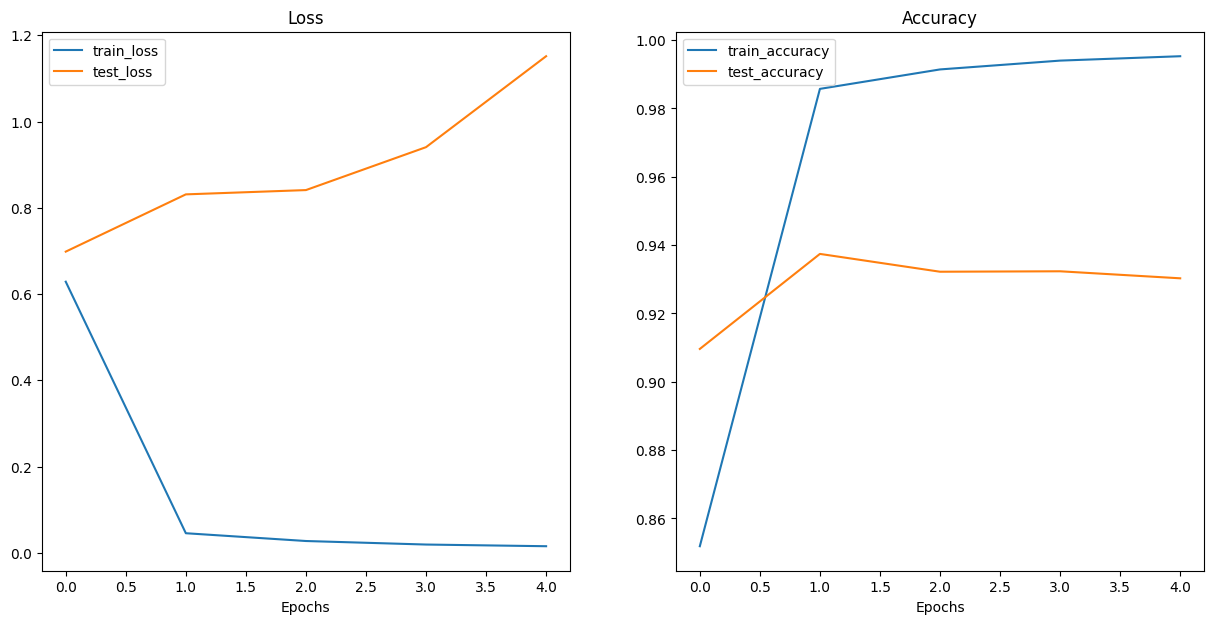

In [ ]:
plot_loss_curves(model_0_results)

# Train and Test ViT Model

## Load Model

In [ ]:
import torchvision.models as models

vit_weights = models.ViT_B_16_Weights.DEFAULT
vit_model = models.vit_b_16(weights=vit_weights)

print("Models loaded successfully!")

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:02<00:00, 153MB/s]


Models loaded successfully!


In [ ]:
print(vit_model)

VisionTransformer(
  (conv_proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  (encoder): Encoder(
    (dropout): Dropout(p=0.0, inplace=False)
    (layers): Sequential(
      (encoder_layer_0): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_attention): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
        )
        (dropout): Dropout(p=0.0, inplace=False)
        (ln_2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (mlp): MLPBlock(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=3072, out_features=768, bias=True)
          (4): Dropout(p=0.0, inplace=False)
        )
      )
      (encoder_layer_1): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_a

In [ ]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

## Create Transforms

In [ ]:
# Write transform for image
data_transform = transforms.Compose([

    # Resize the images to 64x64
    transforms.Resize(size=(224, 224)),

    # Turn the image into a torch.Tensor
    transforms.ToTensor() # this also converts all pixel values from 0 to 255 to be between 0.0 and 1.0
])

## Create Image folder

In [ ]:
# Use ImageFolder to create dataset(s)
from torchvision import datasets
train_data = datasets.ImageFolder(root=train_dir, # target folder of images
                                  transform=data_transform, # transforms to perform on data (images)
                                  target_transform=None) # transforms to perform on labels (if necessary)

test_data = datasets.ImageFolder(root=test_dir,
                                 transform=data_transform)

print(f"Train data:\n{train_data}\nTest data:\n{test_data}")

Train data:
Dataset ImageFolder
    Number of datapoints: 140567
    Root location: /content/fruits-360-100x100/Training
    StandardTransform
Transform: Compose(
               Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
               ToTensor()
           )
Test data:
Dataset ImageFolder
    Number of datapoints: 46834
    Root location: /content/fruits-360-100x100/Test
    StandardTransform
Transform: Compose(
               Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
               ToTensor()
           )


## Create dataloader

In [ ]:
# Turn train and test Datasets into DataLoaders
from torch.utils.data import DataLoader
train_dataloader = DataLoader(dataset=train_data,
                              batch_size=BATCH_SIZE, # how many samples per batch?
                              num_workers=NUM_WORKERS, # how many subprocesses to use for data loading? (higher = more)
                              shuffle=True) # shuffle the data?

test_dataloader = DataLoader(dataset=test_data,
                             batch_size=BATCH_SIZE,
                             num_workers=NUM_WORKERS,
                             shuffle=False) # don't usually need to shuffle testing data

train_dataloader, test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x7bfdb889ac10>,
 <torch.utils.data.dataloader.DataLoader at 0x7bfdb53a50f0>)

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

## Train a forward pass

In [ ]:
# 1. Get a batch of images and labels from the DataLoader
img_batch, label_batch = next(iter(train_dataloader))

# 2. Get a single image from the batch and unsqueeze the image so its shape fits the model
img_single, label_single = img_batch[0].unsqueeze(dim=0), label_batch[0]
print(f"Single image shape: {img_single.shape}\n")

# 3. Perform a forward pass on a single image
vit_model = vit_model.to(device)  # <-- This is the missing piece!
vit_model.eval()

with torch.inference_mode():
    pred = vit_model(img_single.to(device))

# 4. Print out what's happening and convert model logits -> pred probs -> pred label
print(f"Output logits:\n{pred}\n")
print(f"Output prediction probabilities:\n{torch.softmax(pred, dim=1)}\n")
print(f"Output prediction label:\n{torch.argmax(torch.softmax(pred, dim=1), dim=1)}\n")
print(f"Actual label:\n{label_single}")

Single image shape: torch.Size([1, 3, 224, 224])

Output logits:
tensor([[-6.9357e-01, -1.8868e+00, -7.5364e-01, -1.3545e+00, -1.6013e+00,
          2.5706e+00, -1.3958e+00, -1.2158e-01, -5.4573e-01,  4.3816e-01,
          6.1308e-02, -6.5943e-01, -4.2091e-01, -1.5286e-01, -8.3242e-01,
         -3.9208e-01, -4.3328e-01, -1.0742e+00, -4.9570e-01, -5.9768e-01,
          3.5549e-01,  1.5714e+00,  7.2583e-01,  4.9524e-01, -5.0322e-01,
         -5.8274e-01,  2.4019e-01, -7.9645e-01, -9.0974e-02,  4.9229e-02,
         -4.3583e-01, -7.7313e-01,  5.8878e-01, -2.7946e-01,  2.0515e-01,
          3.6848e-01,  1.0314e+00, -1.1135e-01, -6.0886e-02, -7.1222e-01,
         -1.4427e+00, -1.5856e+00, -1.4025e+00, -2.5773e-01, -2.5680e-01,
          1.1824e+00, -1.3169e+00,  3.1949e-01, -5.6292e-01, -4.7540e-01,
         -4.1202e-01, -1.4570e-01, -2.2875e-01, -1.1132e-01, -7.3657e-01,
         -9.5778e-01, -1.7843e+00, -1.7624e+00, -5.0556e-01, -1.0527e-01,
         -5.3144e-01, -1.7743e+00, -7.4720e-01,

## Train ViT base model

In [ ]:
# Set random seeds
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# Set number of epochs
NUM_EPOCHS = 5

# Setup loss function and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=vit_model.parameters(), lr=0.001)

# Start the timer
from timeit import default_timer as timer
start_time = timer()

# Train model_0
model_2_results = train(model=vit_model,
                        train_dataloader=train_dataloader,
                        test_dataloader=test_dataloader,
                        optimizer=optimizer,
                        loss_fn=loss_fn,
                        epochs=NUM_EPOCHS)

# End the timer and print out how long it took
end_time = timer()
print(f"Total training time: {end_time-start_time:.3f} seconds")

  0%|          | 0/5 [00:00<?, ?it/s]